# S04 — Perception visuelle : choisir le bon graphique

Un même tableau de chiffres peut conduire à des conclusions très différentes selon la façon dont on le dessine.
Aujourd'hui, nous allons :

1. mesurer ce que l'œil lit bien (et mal) ;
2. diagnostiquer trois graphiques ratés construits sur nos données NYC Taxi ;
3. les refaire correctement ;
4. apprendre à choisir le graphique à partir de la question posée.

Prérequis : les tables `gold_trajets_horaires` et `gold_zones` existent dans PostgreSQL (séance S02).

In [1]:
import sys; sys.path.append("/home/jovyan/work")
from commun.donnees import lire

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

horaires = lire("gold_trajets_horaires")
zones = lire("gold_zones")
horaires["heure_pickup"] = pd.to_datetime(horaires["heure_pickup"])
horaires["heure"] = horaires["heure_pickup"].dt.hour
arr = (horaires[~horaires["arrondissement"].isin(["Unknown", "N/A"])]
       .groupby("arrondissement", as_index=False)
       .agg(courses=("courses", "sum"), revenu=("revenu", "sum")))
arr["prix_moyen"] = arr["revenu"] / arr["courses"]
arr

,arrondissement,courses,revenu,prix_moyen
0,Bronx,5897,233869.88,39.659128
1,Brooklyn,23993,770172.84,32.099897
2,EWR,77,6883.30,89.393506
3,Manhattan,2533131,57835679.80,22.831697
4,Queens,244852,18845002.69,76.964871
5,Staten Island,71,1854.34,26.117465


## 1. Ce que l'œil lit bien

Cleveland et McGill (1984) ont mesuré la précision avec laquelle on compare des quantités selon leur encodage visuel.
Du plus précis au moins précis :

1. **position sur une échelle commune** (barres alignées, points) ;
2. position sur des échelles non alignées ;
3. **longueur** ;
4. angle, pente ;
5. **aire** ;
6. volume, saturation et teinte de couleur.

Testez-le : sans lire les nombres, classez les cinq valeurs ci-dessous sur le camembert, puis sur les barres.

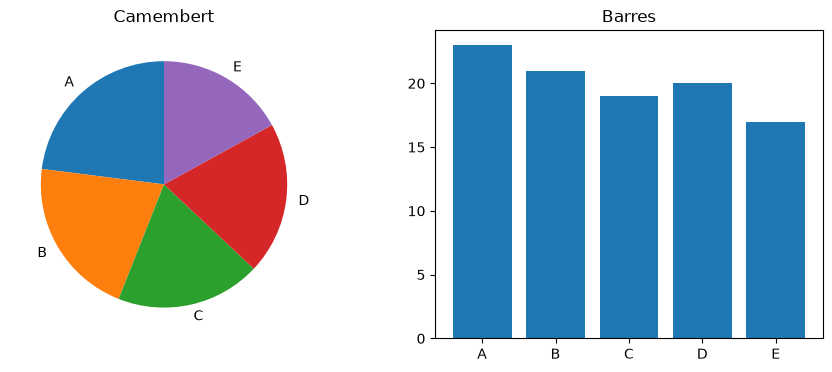

In [2]:
valeurs = pd.Series([23, 21, 19, 20, 17], index=list("ABCDE"))
fig, (g, d) = plt.subplots(1, 2, figsize=(11, 4))
g.pie(valeurs, labels=valeurs.index, startangle=90); g.set_title("Camembert")
d.bar(valeurs.index, valeurs); d.set_title("Barres")
plt.show()

Sur le camembert, l'ordre est presque impossible à lire. Sur les barres, il saute aux yeux.
C'est la différence entre un angle et une position sur une échelle commune.

## 2. Atelier : trois graphiques ratés

Pour chacun des trois graphiques :

- écrivez **la question** à laquelle il devrait répondre ;
- listez **tout ce qui ne va pas** (type de graphique, axes, couleurs, titre, unités…) ;
- **refaites-le** dans la cellule prévue, puis justifiez chaque choix en une phrase.

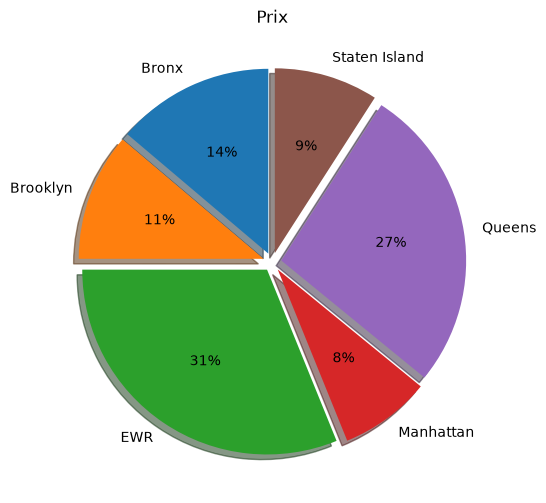

In [3]:
# Graphique A
plt.figure(figsize=(6, 6))
plt.pie(arr["prix_moyen"], labels=arr["arrondissement"], autopct="%1.0f%%",
        explode=[0.05] * len(arr), shadow=True, startangle=90)
plt.title("Prix")
plt.show()

**Graphique A**

- Question visée : …
- Ce qui ne va pas : …

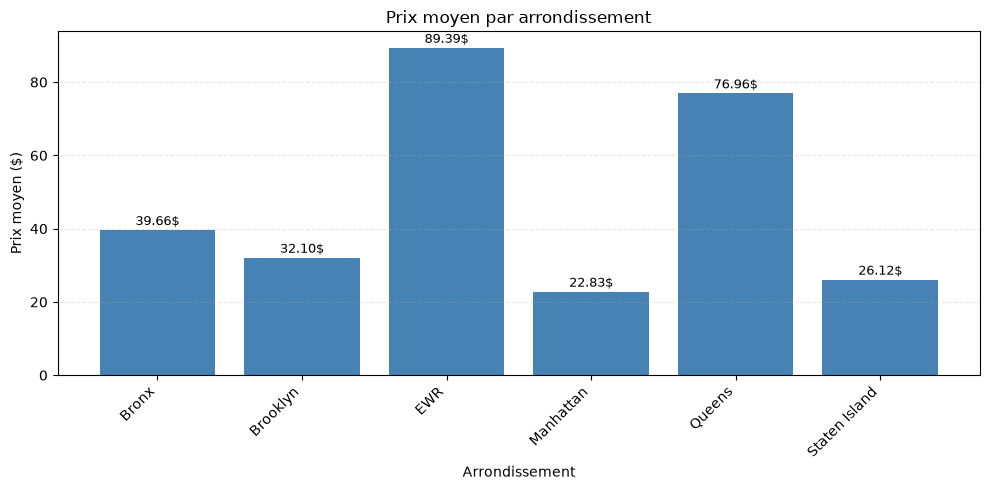

In [12]:
# Votre version du graphique A : graphique en barres sur le prix moyen par zone
plt.figure(figsize=(10, 5))
ax = plt.gca()

bars = ax.bar(arr["arrondissement"], arr["prix_moyen"], color="steelblue")

ax.set_title("Prix moyen par arrondissement")
ax.set_xlabel("Arrondissement")
ax.set_ylabel("Prix moyen ($)")
ax.grid(axis="y", linestyle="--", alpha=0.3)

for bar, value in zip(bars, arr["prix_moyen"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value:.2f}$",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

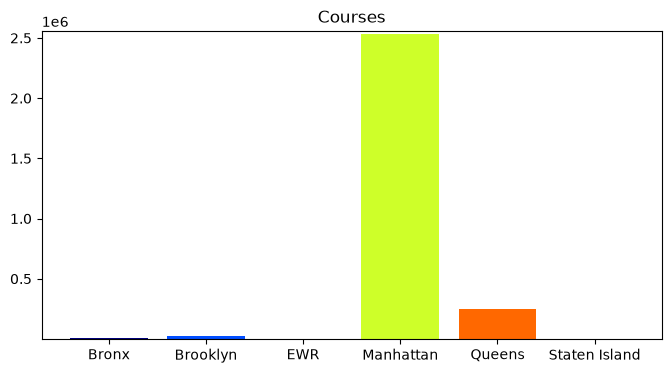

In [4]:
# Graphique B
couleurs = plt.cm.jet(np.linspace(0, 1, len(arr)))
plt.figure(figsize=(8, 4))
plt.bar(arr["arrondissement"], arr["courses"], color=couleurs)
plt.ylim(arr["courses"].min() * 0.95, arr["courses"].max() * 1.01)
plt.title("Courses")
plt.show()

**Graphique B**

- Question visée : …
- Ce qui ne va pas : …

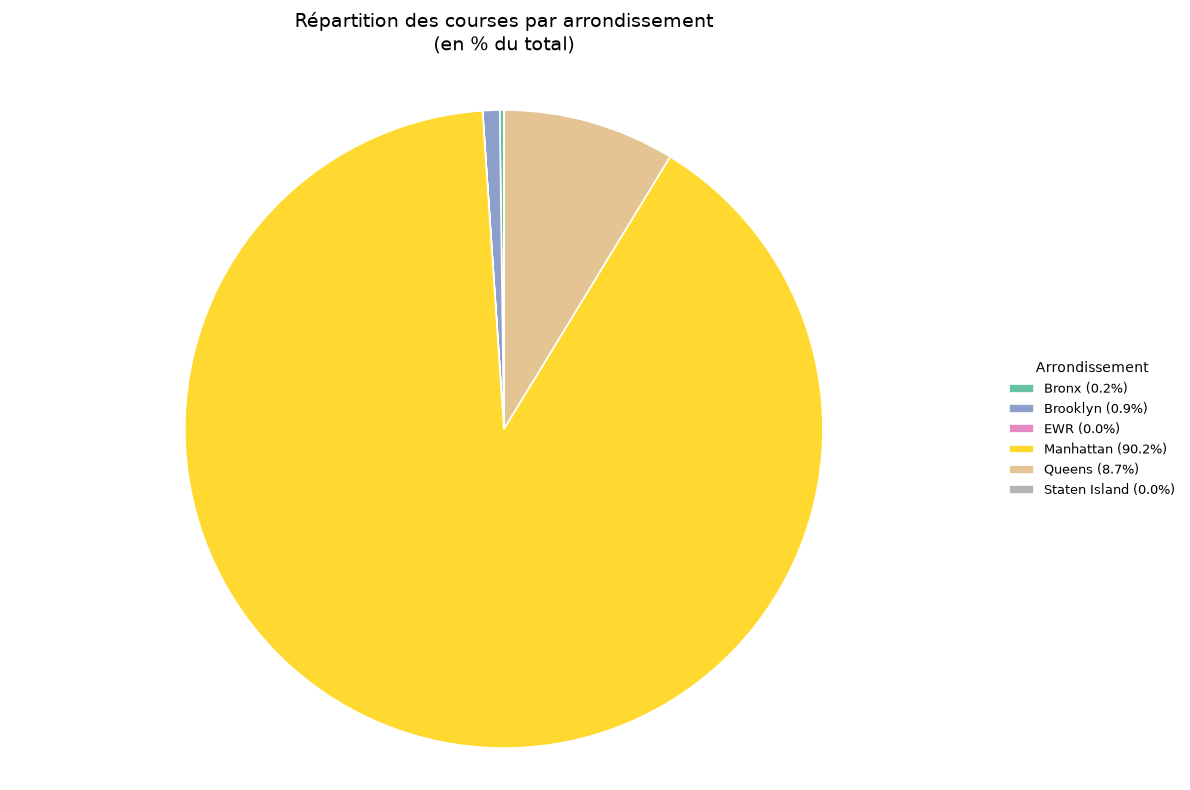

In [19]:
# Votre version du graphique B, couleurs, pas d'unité
# Graphique B adapté : répartition des courses par arrondissement
parts = arr["courses"] / arr["courses"].sum() * 100

fig, ax = plt.subplots(figsize=(12, 8))
colors = plt.cm.Set2(np.linspace(0.1, 1, len(arr)))

wedges, _ = ax.pie(
    parts,
    labels=None,
    startangle=90,
    colors=colors,
    wedgeprops={"edgecolor": "white", "linewidth": 1.2},
    radius=1.0
)

ax.legend(
    wedges,
    [f"{zone} ({pct:.1f}%)" for zone, pct in zip(arr["arrondissement"], parts)],
    title="Arrondissement",
    loc="center left",
    bbox_to_anchor=(1.0, 0.5),
    frameon=False,
    fontsize=9,
    title_fontsize=10
)

ax.set_title("Répartition des courses par arrondissement\n(en % du total)", fontsize=14, pad=20)
ax.axis("equal")
plt.tight_layout()
plt.show()

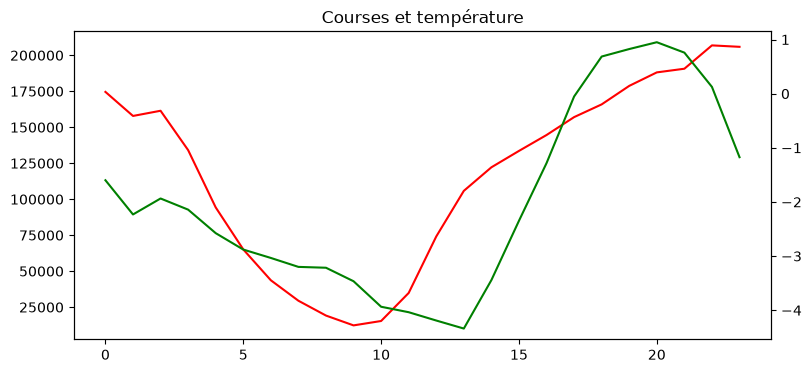

In [5]:
# Graphique C
par_heure = horaires.groupby("heure").agg(courses=("courses", "sum"), temperature=("temperature_c", "mean"))
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(par_heure.index, par_heure["courses"], color="red")
ax2 = ax1.twinx()
ax2.plot(par_heure.index, par_heure["temperature"], color="green")
ax2.set_ylim(par_heure["temperature"].min() - 0.2, par_heure["temperature"].max() + 0.2)
plt.title("Courses et température")
plt.show()

**Graphique C**

- Question visée : …
- Ce qui ne va pas : …

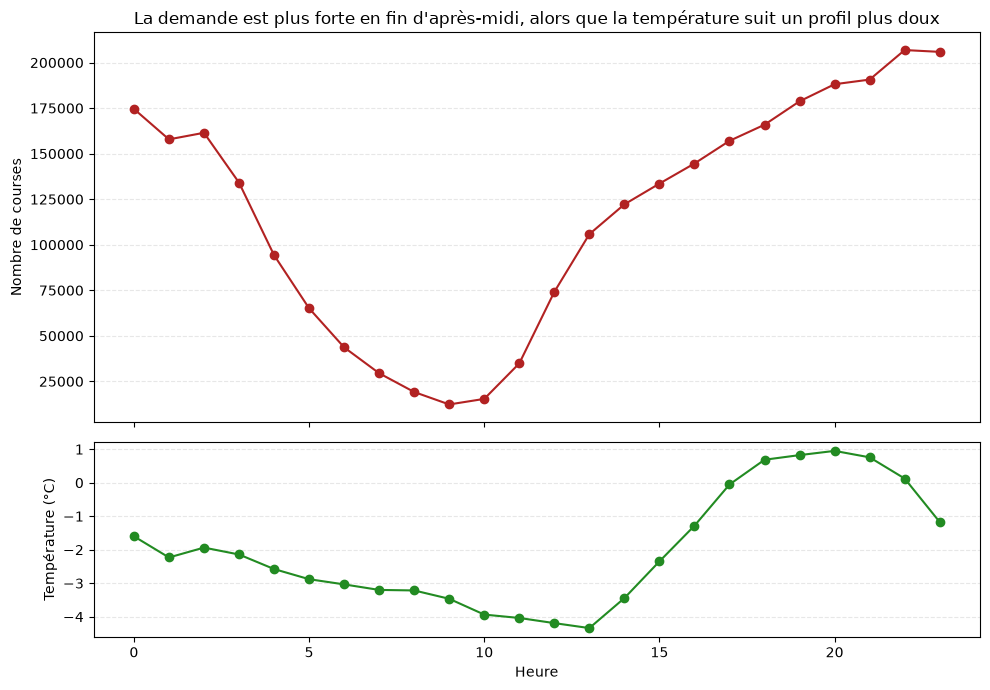

In [20]:
# Votre version du graphique C
# Votre version du graphique C : demande et température par heure
par_heure = (
    horaires.groupby("heure", as_index=False)
    .agg(courses=("courses", "sum"), temperature=("temperature_c", "mean"))
)

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True,
    gridspec_kw={"height_ratios": [2, 1]}
)

ax1.plot(par_heure["heure"], par_heure["courses"], color="firebrick", marker="o")
ax1.set_ylabel("Nombre de courses")
ax1.set_title("La demande est plus forte en fin d'après-midi, alors que la température suit un profil plus doux")
ax1.grid(axis="y", linestyle="--", alpha=0.3)

ax2.plot(par_heure["heure"], par_heure["temperature"], color="forestgreen", marker="o")
ax2.set_xlabel("Heure")
ax2.set_ylabel("Température (°C)")
ax2.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Choisir le graphique à partir de la question

| La question porte sur… | Graphique adapté | À éviter |
|---|---|---|
| une **comparaison** entre catégories | barres horizontales triées, points | camembert à plus de 3 parts, 3D |
| une **évolution** dans le temps | courbe, aires | barres très nombreuses, axe non chronologique |
| une **répartition** d'une variable | histogramme, boîte à moustaches | moyenne seule |
| une **relation** entre deux variables | nuage de points (avec agrégation si gros volume) | double axe |
| une **part d'un tout** (peu de parts) | barre empilée à 100 %, camembert à 2–3 parts | camembert à 8 parts |
| une **géographie** | carte choroplèthe (valeurs normalisées) | carte de valeurs brutes non rapportées |

**Exercice :** pour chacune des questions suivantes, choisissez un graphique, construisez-le et donnez-lui un titre qui énonce la conclusion
(pas seulement le sujet).

1. À quelle heure la demande est-elle la plus forte ?
2. Quelles sont les 10 zones de départ où le prix moyen est le plus élevé ?
3. La distance moyenne des courses varie-t-elle selon l'heure ?

La demande est maximale à 22h, avec 206,885 courses.


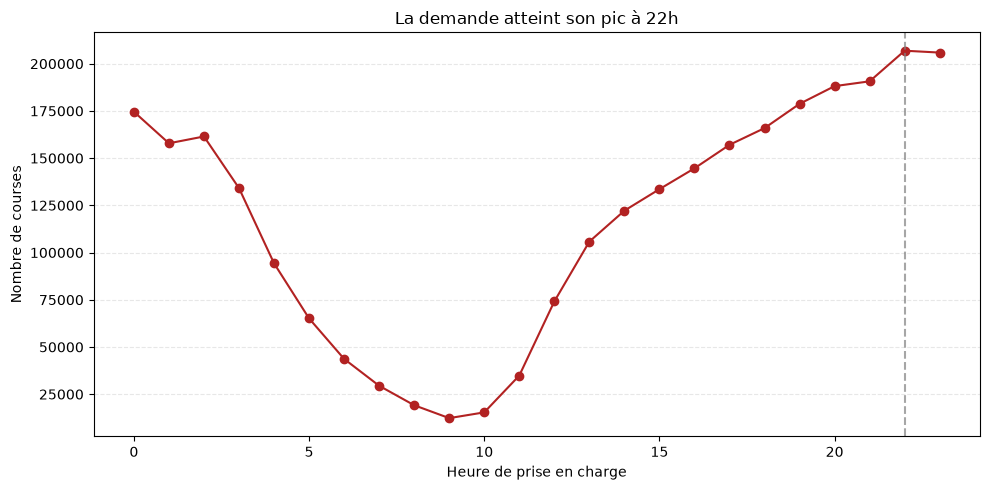

In [30]:
# Question 1
par_heure = (
    horaires.groupby("heure", as_index=False)
    .agg(courses=("courses", "sum"))
)

heure_max = par_heure.loc[par_heure["courses"].idxmax(), "heure"]
max_courses = par_heure["courses"].max()

print(f"La demande est maximale à {heure_max}h, avec {max_courses:,.0f} courses.")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(par_heure["heure"], par_heure["courses"], color="firebrick", marker="o")
ax.axvline(heure_max, color="gray", linestyle="--", alpha=0.7)
ax.set_title(f"La demande atteint son pic à {heure_max}h")
ax.set_xlabel("Heure de prise en charge")
ax.set_ylabel("Nombre de courses")
ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

Les 10 arrondissements les plus chères en moyenne :
arrondissement  prix_moyen
           EWR       89.39
        Queens       76.96
         Bronx       39.66
      Brooklyn       32.10
 Staten Island       26.12
     Manhattan       22.83


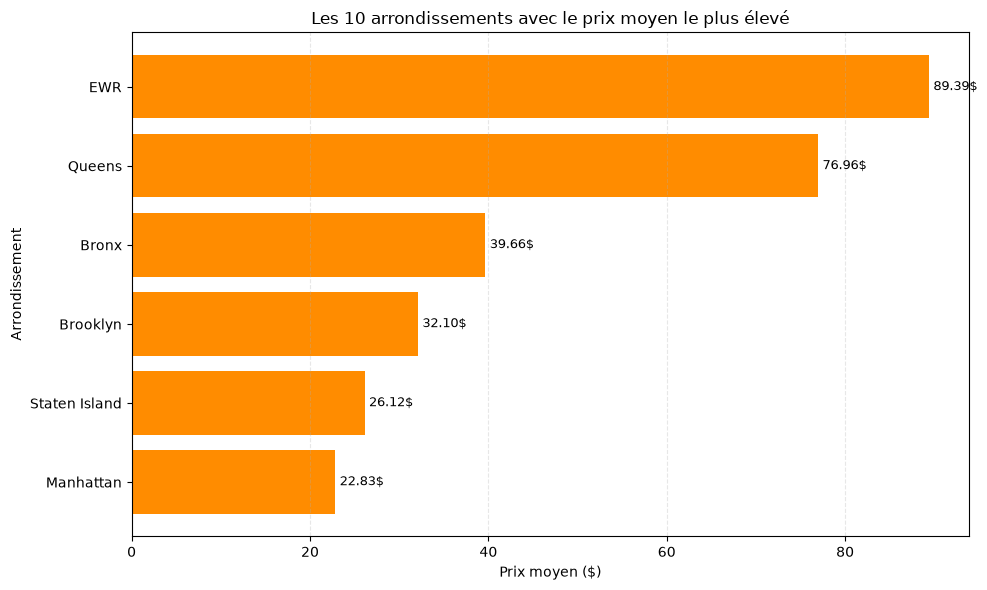

In [32]:
# Question 2
# Les 10 arrondissements avec le prix moyen le plus élevé

top_zones = (
    horaires[~horaires["arrondissement"].isin(["Unknown", "N/A"])]
    .groupby("arrondissement", as_index=False)
    .agg(courses=("courses", "sum"), revenu=("revenu", "sum"))
)

top_zones["prix_moyen"] = top_zones["revenu"] / top_zones["courses"]
top_10 = top_zones.sort_values("prix_moyen", ascending=False).head(10)

print("Les 10 arrondissements les plus chères en moyenne :")
print(top_10[["arrondissement", "prix_moyen"]].round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top_10["arrondissement"], top_10["prix_moyen"], color="darkorange")

ax.invert_yaxis()
ax.set_title("Les 10 arrondissements avec le prix moyen le plus élevé")
ax.set_xlabel("Prix moyen ($)")
ax.set_ylabel("Arrondissement")
ax.grid(axis="x", linestyle="--", alpha=0.3)

for bar, value in zip(bars, top_10["prix_moyen"]):
    ax.text(
        value + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}$",
        va="center",
        ha="left",
        fontsize=9
    )

plt.tight_layout()
plt.show()

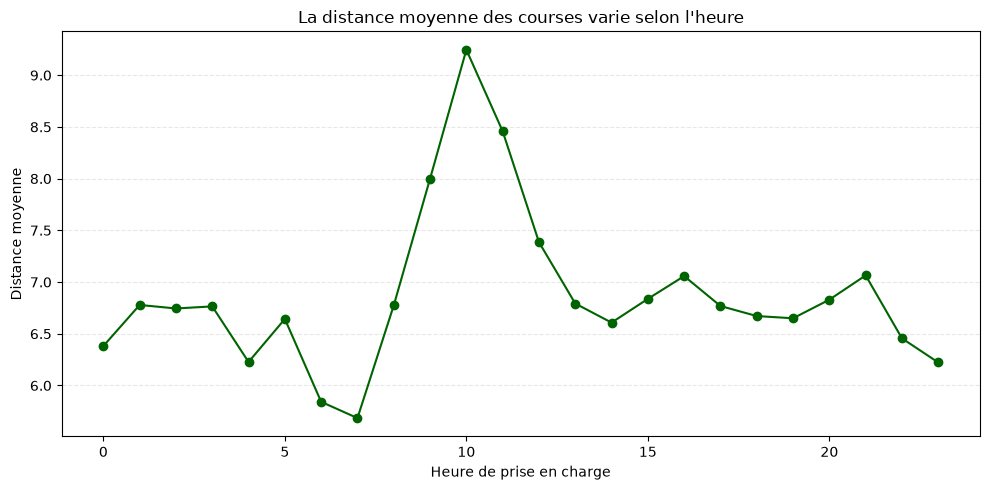

In [33]:
# Question 3
# La distance moyenne des courses varie-t-elle selon l'heure ?

# Détection automatique de la colonne de distance
distance_cols = [c for c in horaires.columns if "distance" in c.lower()]

if not distance_cols:
    raise ValueError("Aucune colonne de distance trouvée dans les données.")

distance_col = distance_cols[0]

par_heure = (
    horaires.groupby("heure", as_index=False)
    .agg(distance_moyenne=(distance_col, "mean"))
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(par_heure["heure"], par_heure["distance_moyenne"], color="darkgreen", marker="o")
ax.set_title("La distance moyenne des courses varie selon l'heure")
ax.set_xlabel("Heure de prise en charge")
ax.set_ylabel("Distance moyenne")
ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

## 4. La couleur

- **Séquentielle** (du clair au foncé) pour une quantité qui va de faible à fort : `viridis`, `Blues`.
- **Divergente** (deux teintes autour d'un centre) pour un écart à une référence : `RdBu`, `PuOr`.
- **Catégorielle** (teintes distinctes) pour des groupes sans ordre : `tab10`, `Set2`.
- À proscrire : `jet` et les arcs-en-ciel, qui créent des frontières qui n'existent pas dans les données
  et sont illisibles pour une partie des daltoniens.

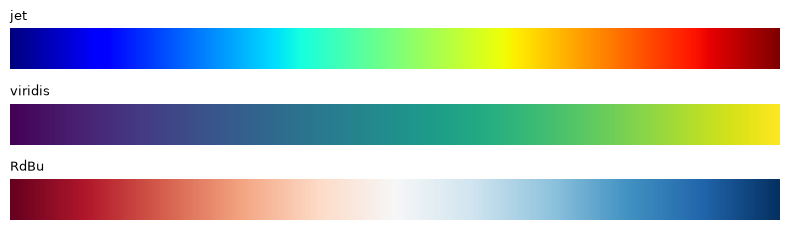

In [34]:
x = np.linspace(0, 1, 256).reshape(1, -1)
fig, axes = plt.subplots(3, 1, figsize=(8, 2.4))
for ax, nom in zip(axes, ["jet", "viridis", "RdBu"]):
    ax.imshow(x, aspect="auto", cmap=nom); ax.set_axis_off(); ax.set_title(nom, fontsize=9, loc="left")
plt.tight_layout(); plt.show()

## À retenir

- On part toujours de **la question**, jamais de l'outil.
- On privilégie la **position sur une échelle commune** ; on se méfie des angles, des aires et de la 3D.
- Un axe de barres commence à **zéro**.
- Le titre énonce **la conclusion** ; les axes ont des **unités**.
- La couleur a un **sens** (séquentielle, divergente, catégorielle) ou n'est pas utilisée.